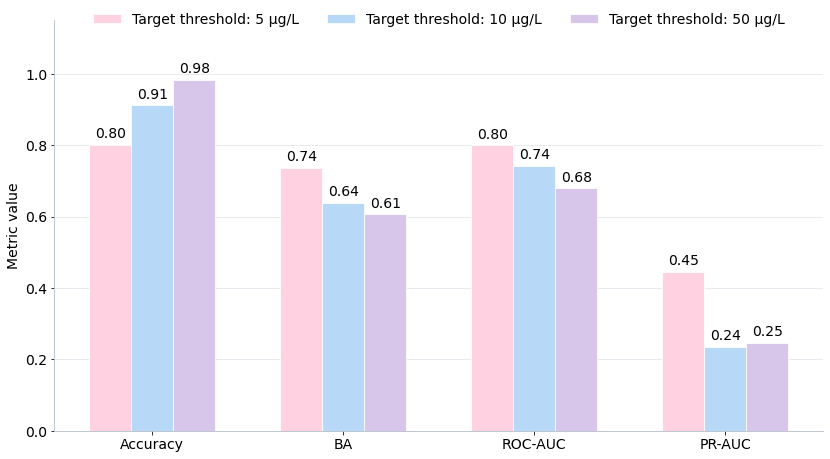

Saved: E:\NO-NC\submission\revise\optimal_models_threshold_metrics.jpg


In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path(r"E:\NO-NC\normalization\revise\reviewer3_threshold_results")
OUTPUT_DIR = Path(r"E:\NO-NC\submission\revise")
OUTPUT_JPG = OUTPUT_DIR / "optimal_models_threshold_metrics.jpg"

thresholds = [5, 10, 50]
metric_columns = ["Accuracy", "Balanced_accuracy", "ROC_AUC", "PR_AUC"]
metric_labels = ["Accuracy", "BA", "ROC-AUC", "PR-AUC"]

# （1）字号统一调整为 16
UNIFIED_FONT_SIZE = 14
FONT_FAMILY = "DejaVu Sans"

records = []
for threshold in thresholds:
    folder = RESULTS_DIR / f"threshold_{threshold}"
    test_df = pd.read_csv(folder / "independent_test_metrics.csv")
    best_df = pd.read_csv(folder / "best_model_by_threshold.csv")
    
    if len(test_df) != 1 or len(best_df) != 1:
        raise ValueError(f"Expected one selected-model row for threshold {threshold}.")
    
    test_row = test_df.iloc[0]
    best_row = best_df.iloc[0]
    if test_row["model"] != best_row["model"] or test_row["feature_set"] != best_row["feature_set"]:
        raise ValueError(f"Model/feature-set mismatch in threshold {threshold} output files.")
    
    for metric in metric_columns:
        records.append({
            "threshold": threshold,
            "metric": metric,
            "value": float(test_row[metric]),
        })

plot_df = pd.DataFrame(records)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 应用统一字号
plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": UNIFIED_FONT_SIZE,
    "axes.titlesize": UNIFIED_FONT_SIZE,
    "axes.labelsize": UNIFIED_FONT_SIZE,
    "xtick.labelsize": UNIFIED_FONT_SIZE,
    "ytick.labelsize": UNIFIED_FONT_SIZE,
})

# （3）换一种更好看、更有质感的莫兰迪色系
colors = {
    5: "#FFD1E1",   # 莫兰迪雾霾蓝
    10: "#B7D8F7",  # 莫兰迪暖taupe灰棕
    50: "#D8C6EA"   # 莫兰迪灰sage绿
}

fig, ax = plt.subplots(figsize=(12, 7.5))

x = np.arange(len(metric_columns))
bar_width = 0.22
offsets = {5: -bar_width, 10: 0.0, 50: bar_width}

for threshold in thresholds:
    vals = [plot_df.loc[(plot_df["threshold"] == threshold) & (plot_df["metric"] == metric), "value"].iloc[0] for metric in metric_columns]
    bars = ax.bar(
        x + offsets[threshold],
        vals,
        width=bar_width,
        color=colors[threshold],
        label=f"Target threshold: {threshold} µg/L",
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )
    # 柱状图数字保留2位小数，并使用统一字号
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=4, fontsize=UNIFIED_FONT_SIZE)

ax.set_ylabel("Metric value")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.15)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", color="#E2E7EC", linewidth=0.8, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#B0BAC5")
ax.spines["bottom"].set_color("#B0BAC5")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.05), fontsize=UNIFIED_FONT_SIZE)

# （2）已删去中间的模型配置备注框

fig.subplots_adjust(left=0.09, right=0.98, bottom=0.12, top=0.88)
fig.savefig(OUTPUT_JPG, dpi=300, format="jpg", bbox_inches="tight", facecolor="white")
plt.show(fig)
plt.close(fig)

print(f"Saved: {OUTPUT_JPG}")